In [349]:
import zipfile 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import *
from sklearn.decomposition import PCA



## Introduction

## Data Preparation

In [350]:
d = pd.read_csv("EVChargingStationUsage.csv")

/var/folders/ts/_x954mrs01g44m904cr4qh8m0000gn/T/ipykernel_39606/55010787.py:1: DtypeWarning: Columns (29,30,32) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv("EVChargingStationUsage.csv")


### Selection of Variables

Since the variable "Org Name" only contains: 'City of Palo Alto', 'City of Palo Alto ', we remove it. Similarly "City", "County", "State/Province". Equally since there are no observations were

In [351]:
d.iloc[0]


Station Name                       PALO ALTO CA / HAMILTON #1
MAC Address                               000D:6F00:015A:9D76
Org Name                                    City of Palo Alto
Start Date                                    7/29/2011 20:17
Start Time Zone                                           PDT
End Date                                      7/29/2011 23:20
End Time Zone                                             PDT
Transaction Date (Pacific Time)               7/29/2011 23:20
Total Duration (hh:mm:ss)                             3:03:32
Charging Time (hh:mm:ss)                              1:54:03
Energy (kWh)                                         6.249457
GHG Savings (kg)                                        2.625
Gasoline Savings (gallons)                              0.784
Port Type                                             Level 2
Port Number                                                 2
Plug Type                                               J1772
EVSE ID 

In [352]:
if "Org Name" in d.columns:
    d=d.drop(["Org Name","City","Country","County","State/Province","MAC Address","Start Time Zone", "End Time Zone","GHG Savings (kg)","Gasoline Savings (gallons)","EVSE ID","System S/N","Model Number",
              "Transaction Date (Pacific Time)","Address 1","Plug In Event Id","User ID","End Date"],axis=1)

### Handling Missing Values and Faulty Observations

In [353]:
l1 = len(d)
d=d.dropna(subset=["Driver Postal Code","Currency","Ended By","Port Type"])
l2= len(d)
print(f"Removed {l1-l2} observations")



Removed 9923 observations


### Setting Datatype

In [365]:
date_columns = [
    "Start Date"
]
duration_columns = [
    "Total Duration (hh:mm:ss)",
    "Charging Time (hh:mm:ss)",
]

for column in date_columns:
    d[column] = pd.to_datetime(d[column], errors="coerce", format="mixed")
for column in duration_columns:
    d[column] = pd.to_timedelta(d[column], errors="coerce")

columns_to_check = date_columns + duration_columns
faulty_rows = d[columns_to_check].isna().any(axis=1)
print(f"Dropping {faulty_rows.sum()} faulty observations")
d = d.loc[~faulty_rows].reset_index(drop=True)



Dropping 0 faulty observations


### Making Dummies

Problem with 900+ unique postal codes. Using:
- The first digit represents a broad geographic region of the U.S. (from 0 in the Northeast to 9 in the West).
- The second and third digits designate a regional Sectional Center Facility (SCF).
- The fourth and fifth digits pinpoint a specific post office, town, or delivery area.

We suggest the following labeling based in postal codes.

In [355]:


sanfran = d[(94000<d["Driver Postal Code"])&(d["Driver Postal Code"]<94300)]
paloalto = d[(94300<=d["Driver Postal Code"])&(d["Driver Postal Code"]<94400)]
sanmateo = d[(94400<=d["Driver Postal Code"])&(d["Driver Postal Code"]<94500)]
marincounty = d[(94500<=d["Driver Postal Code"])&(d["Driver Postal Code"]<94800)]
otherszips = d[(94000>d["Driver Postal Code"])|(d["Driver Postal Code"]>=98000)]

d["Postal San Fran"] = (94000<d["Driver Postal Code"])&(d["Driver Postal Code"]<94300)
d["Postal Palo Alto"] = (94300<=d["Driver Postal Code"])&(d["Driver Postal Code"]<94400)
d["Postal San Mateo"] = (94400<=d["Driver Postal Code"])&(d["Driver Postal Code"]<94450)
d["Postal Marin County"] = (94500<=d["Driver Postal Code"])&(d["Driver Postal Code"]<94800)
d["Postal Other"] = (94000>d["Driver Postal Code"])|(d["Driver Postal Code"]>=98000)




In [356]:
d["Start Year"] = d["Start Date"].dt.year
d["Start Month"] = d["Start Date"].dt.month
d["Start Day"] = d["Start Date"].dt.day
d["Start day_of_week"] = d["Start Date"].dt.dayofweek
d["Start Hour"] = d["Start Date"].dt.hour

In [369]:
cat_vars = ["Port Type","Port Number","Plug Type","Postal Code", "Currency","Ended By"]


df_all_numbers = pd.get_dummies(d,columns=cat_vars).drop(["Start Date","Station Name"],axis=1)
df_all_numbers["Total Duration (hh:mm:ss)"] = df_all_numbers["Total Duration (hh:mm:ss)"].dt.seconds
df_all_numbers["Charging Time (hh:mm:ss)"] = df_all_numbers["Charging Time (hh:mm:ss)"].dt.seconds

X = df_all_numbers.to_numpy() # CONFIRM THAT ONE VAR IS DROPPED FOR REFREECNE 

## Clustering

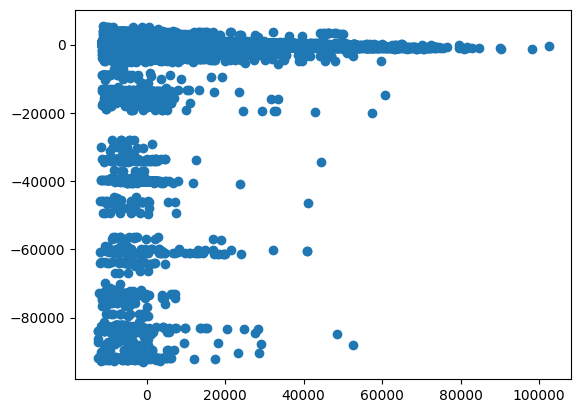

In [373]:
pca = PCA(n_components=2).fit_transform(X)
plt.scatter(pca[:,0],pca[:,1])

## Prediction

## Appendix

|Variable|Explanation| Included |
|----|-----|---- |
|Station Name|xxx| Yes|
|Mac Adress|xxx| No|
|Org Name |xxx| No|
|Start Date|xxx| Yes|
|Start Time Zone|xxx| No|
|End Date|xxx| Yes|
|End Time Zone|xxx| No|
|Transaction Date (Pacific Time)|xxx| No|
|Total Duration (hh:mm:ss)|xxx| Yes|
|Charging Time (hh:mm:ss)|xxx| Yes|
|Energy (kWh)|xxx| Yes|
|GHG Savings (kg)|xxx| No|
|Gasoline Savings (gallons)|xxx| No|
|Port Type|xxx| No|
|Port Number|xxx| No|
|Plug Type|xxx| |
|Latitude|xxx| |
|Longitude|xxx| |
|EVSE ID'|xxx| No|
|Address 1|xxx| No|
|City|xxx|No |
|State/Province|xxx| No|
|Country|xxx| No|
|Currency|xxx| No|
|Fee|xxx| No|
|Ended By'|xxx| Yes|
|Plug In Event Id|xxx| No|
|Driver Postal Code|xxx| Yes|
|User ID|xxx| No|
|System S/N|xxx| No|
|Model Number|xxx| No|

